# Placing a published score in the distribution of its own protocol: the 0.943 of the stacking ensemble

**Question:** Where does a published random-split score sit in its own protocol?

**Level 3: State of the art** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts, 04-benchmark-protocol/02-scores-the-null-and-the-interval · Reading time: about 35 minutes

## Objectives

The most recent published predictor on this corpus is a stacking ensemble reported at a variance explained of 0.943, from one random 80/20 split. A single number cannot say whether that split was typical. This notebook refits the published method on the engine, repeats its protocol 100 times, and asks where 0.943 falls among the results the protocol itself gives.

By the end you will have:

- refitted the stacking ensemble and the polynomial-kernel support vector regression, the two predictors whose parameters the source states, on 100 random draws and put each published figure among its own results;
- repeated the draws after collapsing duplicated input vectors, to test whether duplicates explain the gap;
- held a whole campaign out for the same predictors, and set the product's classical equation beside them to see whether the protocol changes its score.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The published scores 0.943 (stacking) and 0.578 (support vector, polynomial) | Sui et al. 2025, https://doi.org/10.3390/app15031254 | numeric facts reused with citation (open access, CC BY) | `bf.PUBLISHED_RANDOM_SPLIT_R2` inside the `blastfrag` wheel |

Nothing is read from a baked file: every distribution below is recomputed by refitting the predictors on the corpus.

## Method

For a predictor and a protocol, the engine produces one score per draw. The published figure is placed in that distribution: the share of draws that fall below it says whether it is a typical result of the protocol or a favourable one. Only the two predictors whose parameters the source states without ambiguity are placed. The source prints two parameter sets for its random forest and its gradient boosting and does not say which produced the 0.797 and 0.758 it reports, so those two are left out and not compared with an arbitrary choice.

The draws are the engine's `repeated_random_splits` (100 splits, seeds 0 to 99) and `repeated_deduplicated_splits`; every fold refits the predictor from scratch, and the score is `r2_identity`, the variance explained about the identity line. What to look for: whether 0.943 is typical of its protocol, whether duplicated inputs explain what it is not, and what holding a campaign out does.

### Step 1: one draw, refitted

Before the 100 draws, the cell refits both predictors on the single split of seed 0 and puts the result beside the published figure, so the difference between a draw and a distribution is visible at once.

In [2]:
# One seeded draw, refitted for the two predictors whose parameters the source states
factories = bf.default_arms()
published = bf.PUBLISHED_RANDOM_SPLIT_R2
split = bf.random_split(train, seed=0)
rows = []
for name, figure in published.items():
    model = factories[name]().fit(split.train)
    seed_zero = bf.score(split.test, model.predict(split.test)).r2_identity
    rows.append((name, f"{figure:.3f}", f"{seed_zero:.4f}"))
print(f"{split.protocol} | seed {split.seed} | {len(split.train)} training, {len(split.test)} test")
show_table(["predictor", "published, one draw", "seed 0, refitted here"], rows)

random-8020 | seed 0 | 78 training, 19 test


predictor,"published, one draw","seed 0, refitted here"
stacking,0.943,0.6933
svr-poly,0.578,0.2211


On the split of seed 0, with 78 blasts for training and 19 for test, the refitted stacking ensemble scores 0.6933 where the paper reports 0.943, and the support vector regression scores 0.2211 where the paper reports 0.578. One draw of the published method on the same rows does not return the published number, and the two draws differ by a large amount from the figures. That alone does not say the paper is wrong: a single split of 19 test blasts is noisy, and the engine's parameters are the ones the source states. It says the next question is the distribution of draws, not the value of one.

## State of the art

- **Sui, Zhou, Zhao, Yang and Zou 2025** (https://doi.org/10.3390/app15031254) fit a stacking ensemble of a random forest and gradient boosting under a linear meta-learner on the 97 blasts and report a variance explained of 0.943 on one random 80/20 split. The SDD research basis records that the authors tried cross-validation and removed it, so the single split is the whole evidence.
- **Amoako, Jha and Zhong 2022** (https://doi.org/10.3390/mining2020013) fit support vector regressors with two kernels on the same rows and reach the opposite kernel conclusion from the 2025 study.
- Resampling that ignores dependence in the data can seriously underestimate prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

The claim "a learned ensemble predicts fragmentation at 0.94" therefore rests on a single draw, with no spread and no campaign held out. The steps below run that published method, through the engine's implementation of it, on the same rows and under the product's protocols.

### Step 2: 100 random draws

The cell fits each predictor on every draw's training rows, scores the test rows, and collects the 100 values. It takes about half a minute because the stacking ensemble refits a forest and a boosted model each time. The table places the published figure among the draws, and the histograms draw it as a line.

predictor,published,median draw,10 %,90 %,draws below the published
stacking,0.943,0.7033,0.529,0.835,100 of 100
svr-poly,0.578,0.3947,0.169,0.627,83 of 100


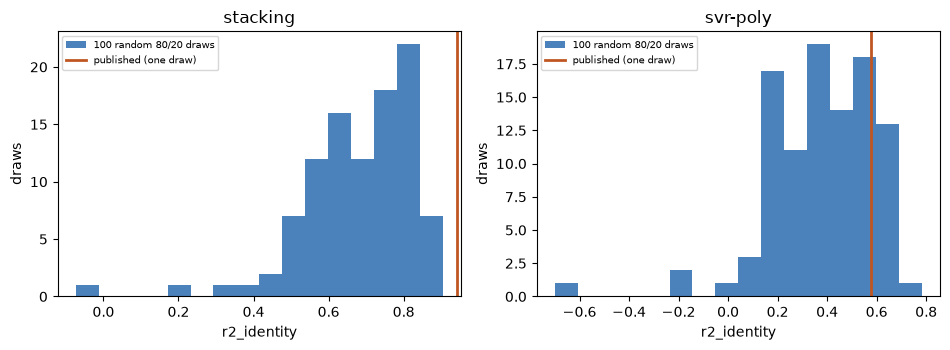

In [3]:
# One score per random 80/20 draw, for 100 draws, with the published figure placed among them
def draw_scores(name, splits):
    # One variance-explained value per split, each fold refitted from scratch
    values = []
    for draw in splits:
        model = factories[name]().fit(draw.train)
        values.append(bf.score(draw.test, model.predict(draw.test)).r2_identity)
    return np.array(values)


random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
random_scores = {name: draw_scores(name, random_draws) for name in published}
rows = []
for name, figure in published.items():
    v = random_scores[name]
    low, high = np.quantile(v, [0.1, 0.9])
    below = int((v < figure).sum())
    rows.append((name, f"{figure:.3f}", f"{np.median(v):.4f}", f"{low:.3f}", f"{high:.3f}", f"{below} of {len(v)}"))
show_table(["predictor", "published", "median draw", "10 %", "90 %", "draws below the published"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, (name, figure) in zip(axes, published.items()):
    ax.hist(random_scores[name], bins=16, color="#2b6cb0", alpha=0.85, label="100 random 80/20 draws")
    ax.axvline(figure, color="#c05621", lw=2, label="published (one draw)")
    ax.set_xlabel("r2_identity")
    ax.set_ylabel("draws")
    ax.set_title(name)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

For the stacking ensemble the 100 random draws have a median of 0.7033 and run from 0.529 at the 10th percentile to 0.835 at the 90th, and all 100 of them fall below the published 0.943, which sits to the right of the whole histogram. The support vector regression is different: its median is 0.3947, its 10th to 90th range is 0.169 to 0.627, and 83 of the 100 draws fall below the published 0.578, so that figure is a favourable draw but a possible one. The first panel therefore says the stacking figure is not a typical result of its own protocol, and the second says the other published figure is. The figure does not say why: a lucky split, a different parameter set or a different feature preparation in the source would all produce it.

### Step 3: do the duplicates explain the gap?

A random split places twins of a test blast in training, as the first notebook of this topic counted. If duplicates explained the gap between a published figure and a typical draw, collapsing them first would lower the scores. The cell repeats both predictors on 100 deduplicated draws and compares the medians; the boxplots set the two protocols side by side with the published line.

predictor,random median,deduplicated median,difference,lowest random draw,lowest deduplicated draw
stacking,0.7033,0.6995,-0.0038,-0.07,-0.11
svr-poly,0.3947,0.3959,+0.0012,-0.70,-10.88


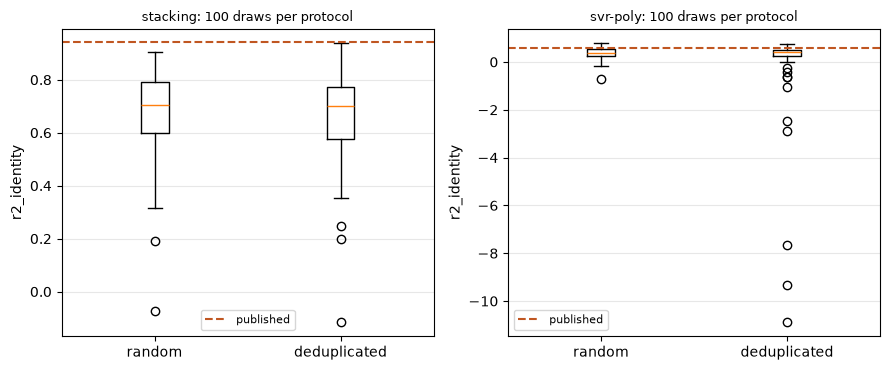

In [4]:
# The same two predictors on 100 deduplicated draws, against the random draws
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
dedup_scores = {name: draw_scores(name, dedup_draws) for name in published}
rows = []
for name in published:
    random_median, dedup_median = np.median(random_scores[name]), np.median(dedup_scores[name])
    lowest = (random_scores[name].min(), dedup_scores[name].min())
    rows.append((name, f"{random_median:.4f}", f"{dedup_median:.4f}", f"{dedup_median - random_median:+.4f}",
                 f"{lowest[0]:.2f}", f"{lowest[1]:.2f}"))
show_table(["predictor", "random median", "deduplicated median",
            "difference", "lowest random draw", "lowest deduplicated draw"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8), sharey=False)
for ax, (name, figure) in zip(axes, published.items()):
    ax.boxplot([random_scores[name], dedup_scores[name]], tick_labels=["random", "deduplicated"])
    ax.axhline(figure, color="#c05621", lw=1.5, ls="--", label="published")
    ax.set_ylabel("r2_identity")
    ax.set_title(f"{name}: 100 draws per protocol", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

Collapsing the duplicates barely moves the medians: the stacking ensemble goes from 0.7033 to 0.6995 and the support vector regression from 0.3947 to 0.3959. The boxes of the two protocols overlap almost entirely, so the twins of the first notebook do not explain why the published 0.943 lies above every draw. The lowest draws differ more: the stacking ensemble's worst draw is -0.07 at random and -0.11 deduplicated, and the support vector regression drops from -0.70 to -10.88, a handful of deduplicated draws on which a polynomial kernel extrapolates badly. The figure shows that duplicates are not the cause; it does not show what the cause of the support vector regression's outliers is.

### Step 4: the campaign held out

The cell scores the same two predictors with each campaign held out in turn, pooling the out-of-fold predictions, and adds two predictors that do not learn from the training rows' sizes: the product's classical equation, `kuznetsov`, and the null. For each one the difference between the random median and the held-out score is the protocol gap.

In [5]:
# Leave one site out for the same predictors, beside the product's classical arm and the null
compared = [*published, "kuznetsov", "null"]
held_out = {}
for name in compared:
    tested, predicted = [], []
    for fold in bf.leave_one_site_out(train):
        model = factories[name]().fit(fold.train)
        tested += list(fold.test)
        predicted += model.predict(fold.test)
    held_out[name] = bf.score(tested, predicted).r2_identity
for name in ("kuznetsov", "null"):
    random_scores[name] = draw_scores(name, random_draws)
rows = []
for name in compared:
    median = np.median(random_scores[name])
    low, high = np.quantile(random_scores[name], [0.1, 0.9])
    gap = median - held_out[name]
    rows.append((name, f"{median:.4f}", f"{low:.3f} to {high:.3f}", f"{held_out[name]:.4f}", f"{gap:.4f}"))
show_table(["predictor", "random median", "random draws, 10 to 90 %",
            "held out by campaign", "protocol gap"], rows)

predictor,random median,"random draws, 10 to 90 %",held out by campaign,protocol gap
stacking,0.7033,0.529 to 0.835,-0.0345,0.7379
svr-poly,0.3947,0.169 to 0.627,-4.5457,4.9404
kuznetsov,0.3026,-0.355 to 0.681,0.3112,-0.0086
null,-0.0362,-0.242 to -0.001,-0.2163,0.1800


With the campaign held out, the stacking ensemble falls from a random median of 0.7033 to -0.0345, a protocol gap of 0.7379, and the support vector regression from 0.3947 to -4.5457, a gap of 4.9404. The two predictors that do not learn sizes from the training rows behave differently: the classical equation scores 0.3026 at random and 0.3112 held out, a gap of -0.0086, so the protocol costs it nothing, and the null goes from -0.0362 to -0.2163, a gap of 0.1800 that comes from the moving training mean. The loss is therefore a property of learning from campaigns, not of the held-out campaigns being harder. The table does not say the classical equation is better: its rock factors were derived per campaign from published predictions, so its held-out score is not a blind one.

### Step 5: one picture of three protocols

The last cell puts every comparison on one axis: for each predictor, the range of its random draws between the 10th and 90th percentiles, its held-out score and, for the two published ones, the published figure.

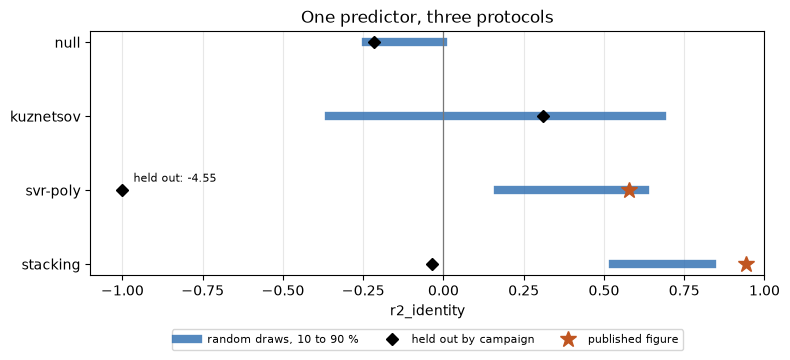

In [6]:
# Every predictor in three protocols: random-draw spread, held-out score and published figure
edge = -1.0
fig, ax = plt.subplots(figsize=(8.0, 3.8))
for row, name in enumerate(compared):
    low, high = np.quantile(random_scores[name], [0.1, 0.9])
    first = row == 0
    ax.plot([low, high], [row, row], lw=6, color="#2b6cb0", alpha=0.8,
            label="random draws, 10 to 90 %" if first else None)
    ax.plot([max(held_out[name], edge)], [row], "D", color="black",
            label="held out by campaign" if first else None)
    if held_out[name] < edge:
        note = f"held out: {held_out[name]:.2f}"
        ax.annotate(note, (edge, row), xytext=(8, 6), textcoords="offset points", fontsize=8)
    if name in published:
        ax.plot([published[name]], [row], "*", color="#c05621", ms=12,
                label="published figure" if name == "stacking" else None)
ax.axvline(0, color="#777", lw=0.9)
ax.set_xlim(edge - 0.1, 1.0)
ax.set_yticks(range(len(compared)), compared)
ax.set_xlabel("r2_identity")
ax.set_title("One predictor, three protocols")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

The picture puts the three protocols on one axis. The stacking ensemble's random draws occupy 0.529 to 0.835 and its published figure sits beyond them at 0.943, while its held-out score is a black diamond just below zero; the support vector regression's published 0.578 falls inside its range of 0.169 to 0.627 but its held-out score, -4.5457, is far off the left edge of the plot. The classical equation's held-out score lies inside its own wide band, -0.355 to 0.681, and the null's band sits around zero with its held-out score at the left end. What the figure shows is the order of the claims: a published figure, a range of results from the same protocol, and the answer to the practitioner's question, which is a different place on the axis. It does not rank the predictors for a new mine.

## Results

**Answer:** the published 0.943 sits above every one of the 100 draws of its own protocol, whose median is 0.7033 and whose 10th to 90th range is 0.529 to 0.835, so it is a favourable result and not the expectation of a random 80/20 split. The other published figure, 0.578 for the polynomial-kernel regression, falls inside its range (median 0.3947, 83 of 100 draws below it). Duplicated inputs do not explain the stacking gap: collapsing them moves the median from 0.7033 to 0.6995. The campaign does, because with each campaign held out the same ensemble scores -0.0345, a protocol gap of 0.7379, and the polynomial-kernel regression -4.5457. The product's classical equation scores 0.3026 at random and 0.3112 held out, so it does not pay for the protocol.

**What this does not show.** It does not show that the 0.943 is wrong as a statement about the authors' split; it shows that one split is one draw of a distribution and that the distribution answers a different question from the practitioner's. The source's two other predictors are left out because it does not say which of two parameter sets produced its figures. The held-out scores themselves rest on ten campaigns, and the classical equation's constants are not blind to the campaign, which the next notebook weighs with intervals.

## Summary

- A published score is one draw: the engine places it in 100 draws of its own protocol, and 0.943 lies above all of them for the stacking ensemble, while 0.578 lies inside the range of the polynomial-kernel regression.
- Duplicated input vectors do not explain the gap (a change of -0.0038 in the median); holding the campaign out does.
- The gap is -0.0086 for the classical equation and 0.7379 for the stacking ensemble, so the cost of the protocol belongs to learning from campaigns.
- Next: notebook 04 runs every predictor under the protocol and applies the pre-declared criterion (level 4).

## References

- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the stacking ensemble, 0.943, 0.578)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression on the same rows)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (dependence in cross-validation)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/